In [1]:
import pandas as pd

from email_outreach.experiment_utils.metric_loader import load_experiment_metrics
from email_outreach.sae_based_mab.metrics import calculate_recall_precision_at_quantiles, calculate_auc
from email_outreach.utils.constants import ROOT_FOLDER
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def get_precisions_recalls(path: Path, quantiles=1 - np.linspace(start=0, stop=1, num=101)):
    experiments: list[list] = load_experiment_metrics(path)
    recalls: list[float] = []
    precisions: list[float] = []
    for experiment in experiments:
        recall, precision = calculate_recall_precision_at_quantiles(experiment,
                                                                                            quantiles=quantiles)[1:3]

        recalls.append(recall)
        precisions.append(precision)

    return recalls, precisions

In [3]:
def get_recalls_auc(path: Path):
    experiments: list[list] = load_experiment_metrics(path)
    recalls_auc: list[float] = []
    for experiment in experiments:
        recall_auc = calculate_auc(experiment)
        recalls_auc.append(recall_auc)

    return recalls_auc

In [4]:
def delta_pct(lhs: np.ndarray, rhs: np.ndarray, decimals: int = 2 ) -> np.ndarray:
    return ((lhs-rhs)*100).round(decimals)

In [5]:
baseline_path: Path = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit" / "baseline"

In [6]:
baseline_recalls, baseline_precisions = get_precisions_recalls(baseline_path)

In [7]:
baseline_recalls_auc = get_recalls_auc(baseline_path)

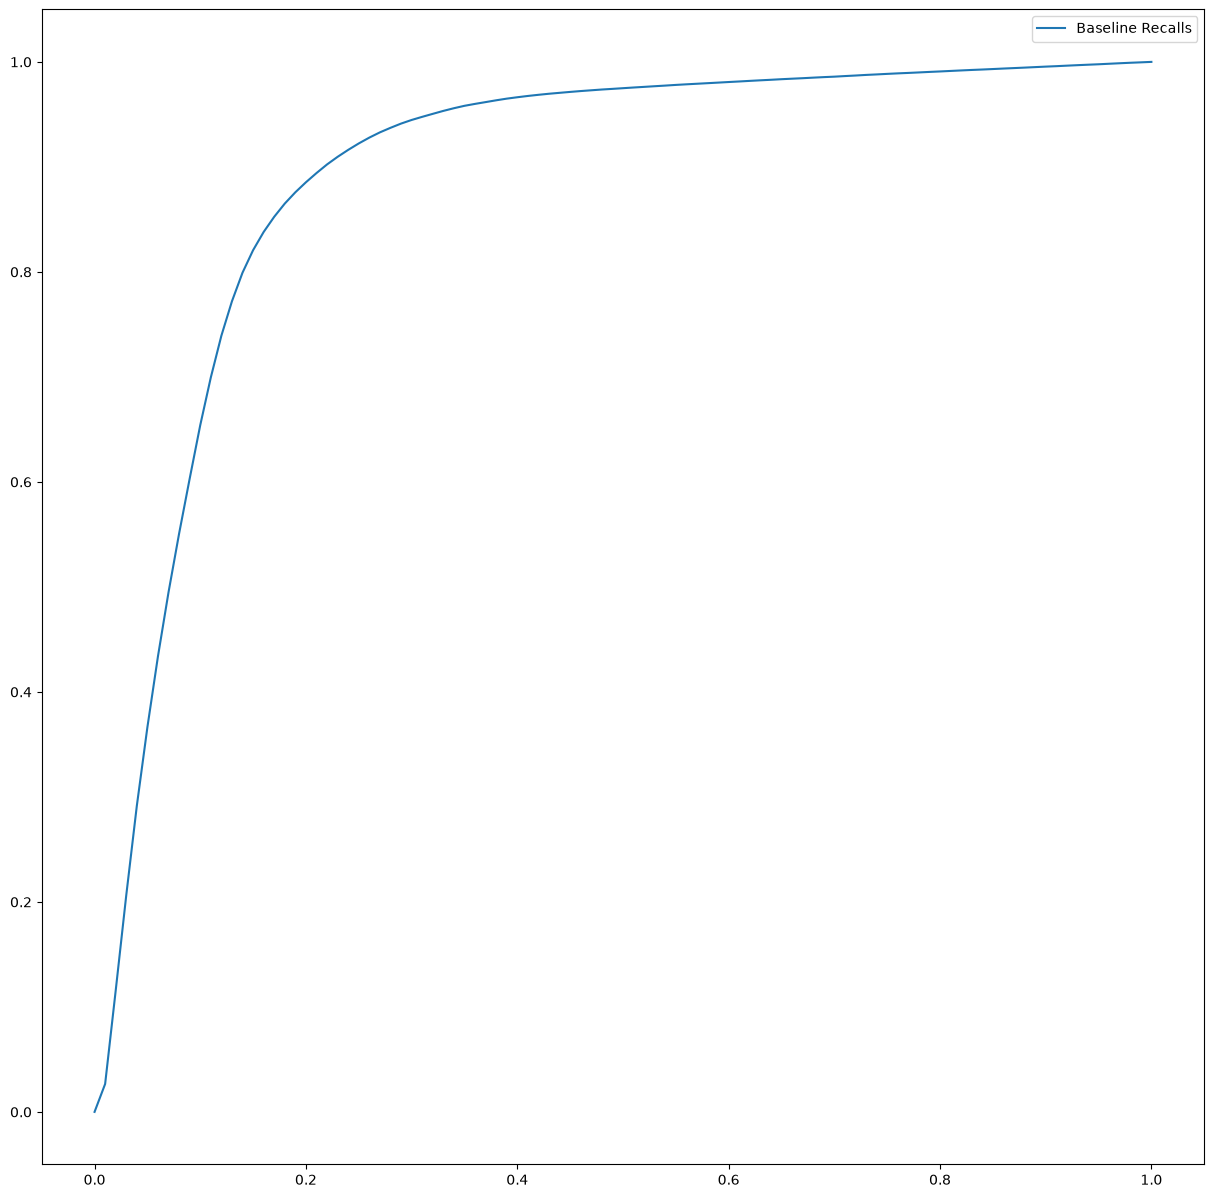

In [8]:
plt.figure(figsize=(15, 15))

plt.plot(np.linspace(start=0, stop=1, num=101), np.array(baseline_recalls).mean(axis=0),
         label="Baseline Recalls")

plt.legend()

In [9]:
np.mean(baseline_recalls_auc)

np.float64(0.8934103422533677)

In [10]:
np.array(baseline_recalls).std(axis=0)[[5,15,25,35]]

array([0.06428801, 0.02238973, 0.01262062, 0.0097658 ])

In [11]:
np.array(baseline_recalls).mean(axis=0)[[5,15,25,35]]

array([0.36641187, 0.82066682, 0.92233555, 0.95816865])

In [12]:
np.array(baseline_recalls).std(axis=0)[[25,50, 75]]

array([0.01262062, 0.00758933, 0.00400111])

In [13]:
np.array(baseline_recalls).mean(axis=0)[[25,50, 75]]

array([0.92233555, 0.97494972, 0.98858403])

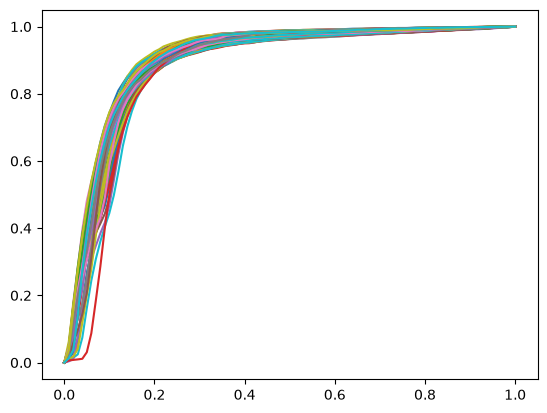

In [14]:

for i in range(len(np.array(baseline_recalls))):
    plt.plot(np.linspace(0,1,101), np.array(baseline_recalls)[i])